# PS-26: Land Use and Land Cover Classification with EuroSAT RGB

**Objective:** classify 64 × 64 RGB satellite patches into 10 land-use/land-cover classes and identify the class pairs most frequently confused by the CNN.

**Reproducibility:** the split uses `random_state=42`; Python, NumPy, and TensorFlow random seeds are also set to 42. The data are split into 70% training, 15% validation, and 15% test sets using stratification. The test set is reserved for final evaluation.

**Run order:** run all cells from top to bottom in Google Colab. The first code cell downloads EuroSAT RGB from Zenodo; the next cell trains and evaluates the model. Training may take several minutes and requires enough Colab disk space and RAM.


In [1]:

import requests
import zipfile
import os

url = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"
zip_path = "/content/EuroSAT_RGB.zip"
extract_dir = "/content/EuroSAT_RGB"

print("Downloading the actual EuroSAT RGB dataset...")

with requests.get(url, stream=True, timeout=60) as r:
    r.raise_for_status()
    with open(zip_path, "wb") as f:
        for chunk in r.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

print("Downloaded size:",
      round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Dataset extracted.")

# Locate the folder containing the 10 class directories
for root, dirs, files in os.walk(extract_dir):
    class_dirs = [
        d for d in dirs
        if d in [
            "AnnualCrop", "Forest", "HerbaceousVegetation",
            "Highway", "Industrial", "Pasture", "PermanentCrop",
            "Residential", "River", "SeaLake"
        ]
    ]
    if len(class_dirs) == 10:
        print("DATASET_DIR =", root)
        print("All 10 classes found successfully.")
        break
else:
    print("Could not locate all 10 class folders. Inspect extracted folders:")
    for root, dirs, files in os.walk(extract_dir):
        print(root, dirs[:12])
        if root.count(os.sep) - extract_dir.count(os.sep) >= 2:
            dirs[:] = []


Downloaded size: 90.27 MB
Dataset extracted.
DATASET_DIR = /content/EuroSAT_RGB/EuroSAT_RGB
All 10 classes found successfully.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
AnnualCrop: 3000 images
Forest: 3000 images
HerbaceousVegetation: 3000 images
Highway: 2500 images
Industrial: 2500 images
Pasture: 2000 images
PermanentCrop: 2500 images
Residential: 3000 images
River: 2500 images
SeaLake: 3000 images

Total images: 27000
Number of classes: 10

Training: 18900
Validation: 4050
Testing: 4050


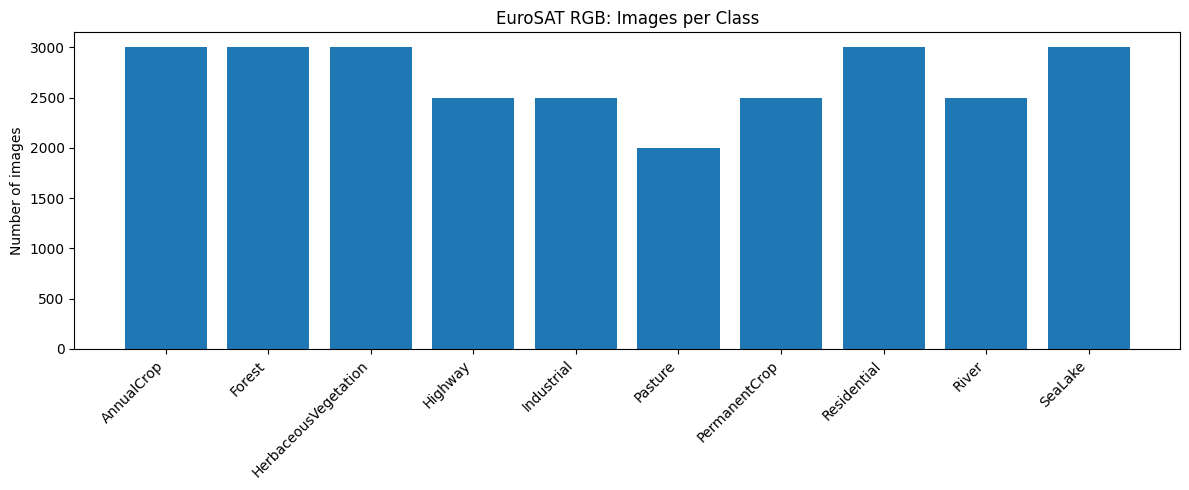

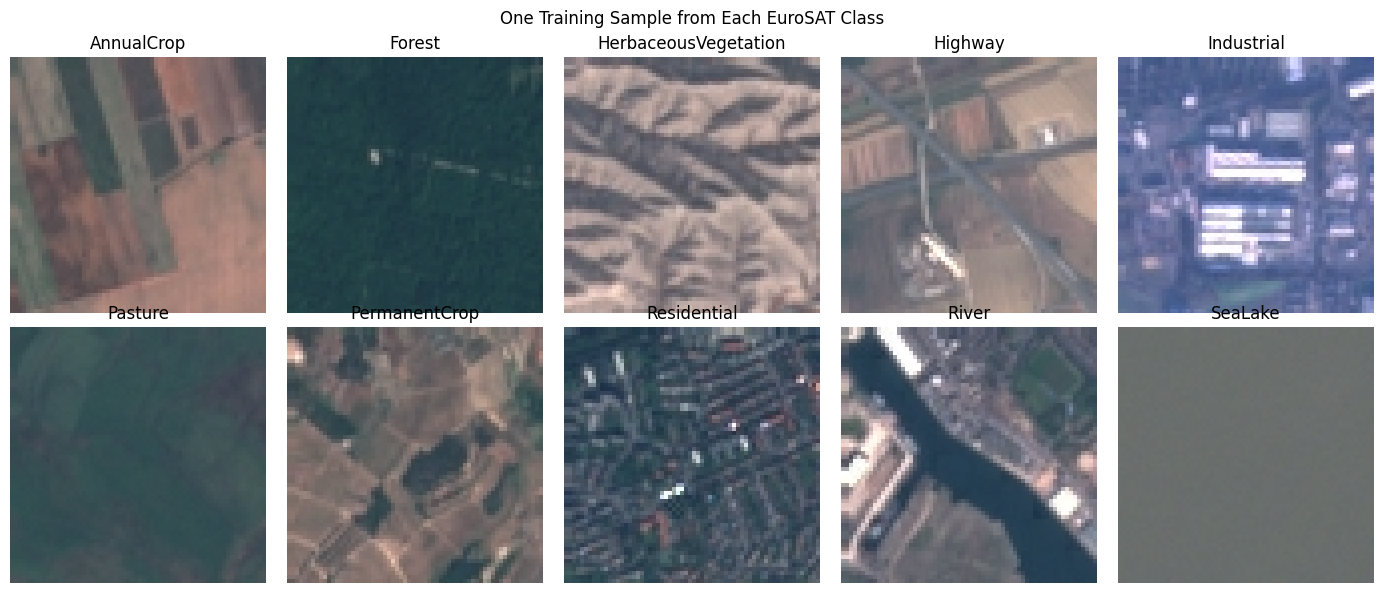

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,498 (1.62 MB)

 Trainable params: 423,050 (1.61 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.6455 - loss: 1.0098 - val_accuracy: 0.1215 - val_loss: 6.5472 - learning_rate: 0.0010
Epoch 2/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.7444 - loss: 0.7310 - val_accuracy: 0.6017 - val_loss: 1.2228 - learning_rate: 0.0010
Epoch 3/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.7816 - loss: 0.6299 - val_accuracy: 0.6289 - val_loss: 1.2442 - learning_rate: 0.0010
Epoch 4/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.8097 - loss: 0.5567 - val_accuracy: 0.6067 - val_loss: 1.3055 - learning_rate: 0.0010
Epoch 5/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.8566 - loss: 0.4264 - val_accuracy: 0.7753 - val_loss: 0.7311 - learning_rate: 5.0000e-04
Epoch 6/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.8711 - loss: 0.3842 - val_accuracy: 0.8274 - val_loss: 0.4685 - learning_rate: 5.0000e-04
Epoch 7/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.8846 -

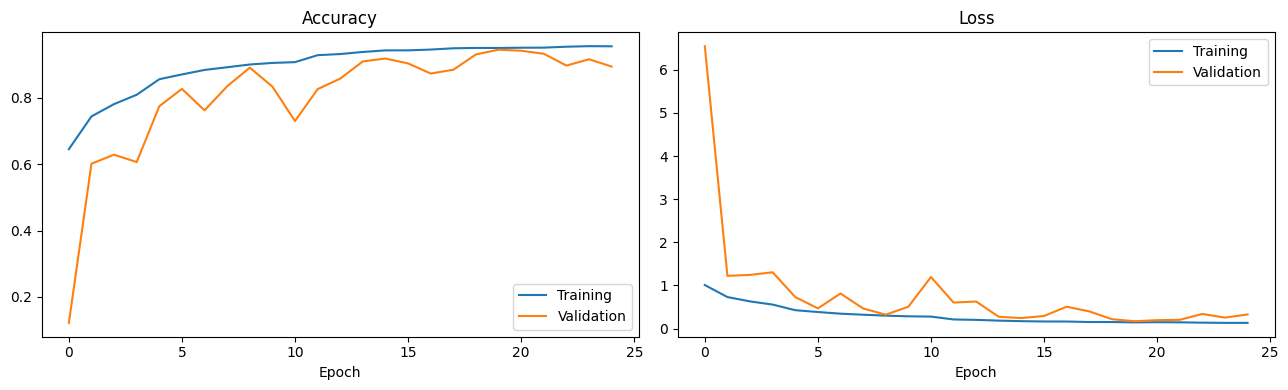

64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9425 - loss: 0.1717

========== TEST RESULTS ==========
Test loss: 0.1717
Test accuracy: 94.25%
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

========== CLASSIFICATION REPORT ==========
                      precision  recall  f1-score    support
AnnualCrop               0.9662  0.8889    0.9259   450.0000
Forest                   0.9868  0.9978    0.9923   450.0000
HerbaceousVegetation     0.9525  0.8911    0.9208   450.0000
Highway                  0.9571  0.8933    0.9241   375.0000
Industrial               0.9346  0.9520    0.9432   375.0000
Pasture                  0.9456  0.9267    0.9360   300.0000
PermanentCrop            0.8828  0.9440    0.9124   375.0000
Residential              0.9310  0.9889    0.9591   450.0000
River                    0.8719  0.9440    0.9065   375.0000
SeaLake                  0.9889  0.9867    0.9878   450.0000
accuracy                 0.9425  0.9425    0.9425     0.9425
macro avg                0.9417  

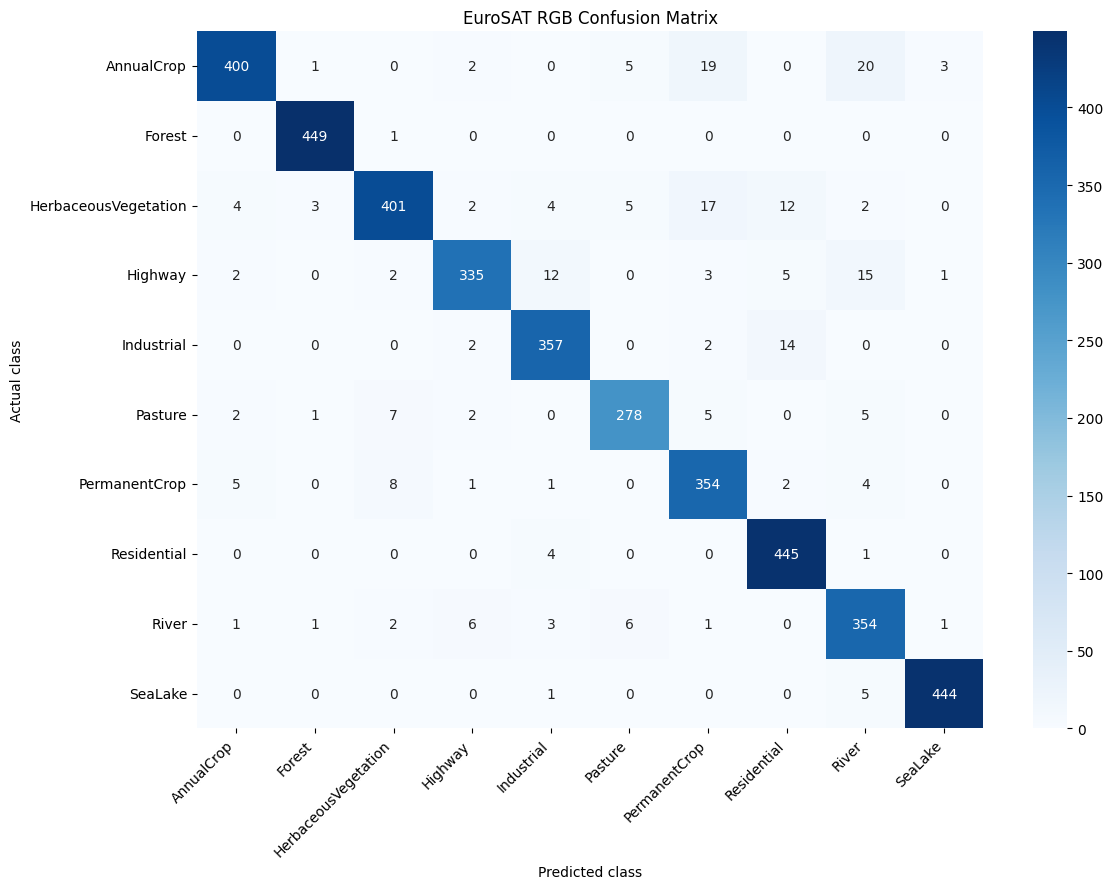


========== TOP 10 CONFUSED CLASS PAIRS ==========
             Class 1       Class 2  Class 1 -> Class 2  Class 2 -> Class 1  Total Confusions
HerbaceousVegetation PermanentCrop                  17                   8                25
          AnnualCrop PermanentCrop                  19                   5                24
          AnnualCrop         River                  20                   1                21
             Highway         River                  15                   6                21
          Industrial   Residential                  14                   4                18
             Highway    Industrial                  12                   2                14
HerbaceousVegetation   Residential                  12                   0                12
HerbaceousVegetation       Pasture                   5                   7                12
             Pasture         River                   5                   6                11
          AnnualCro

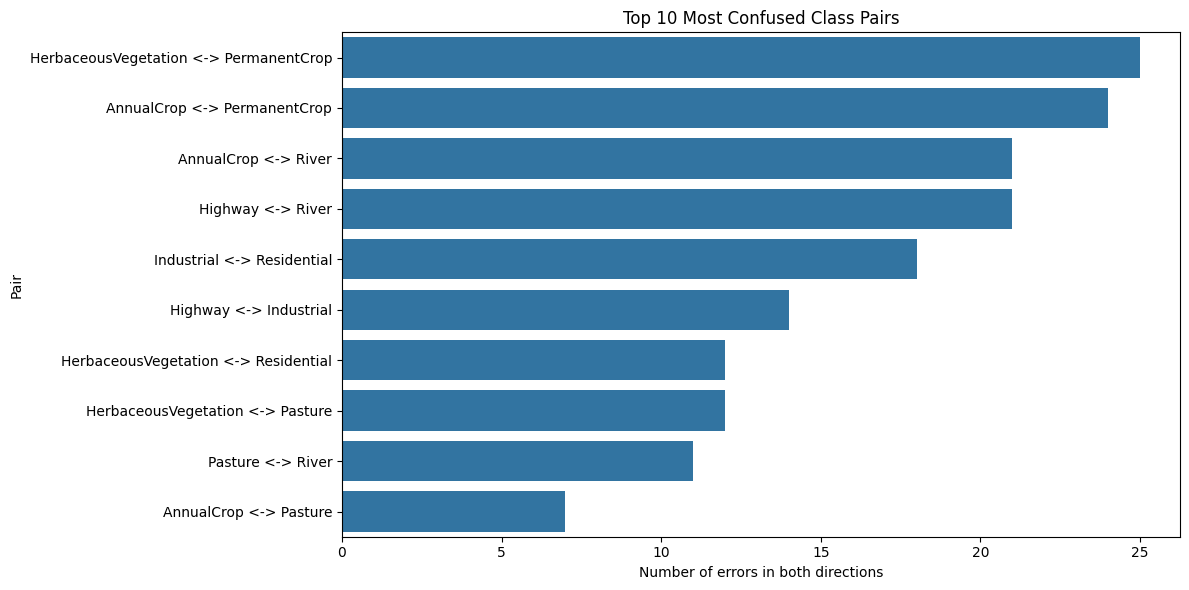

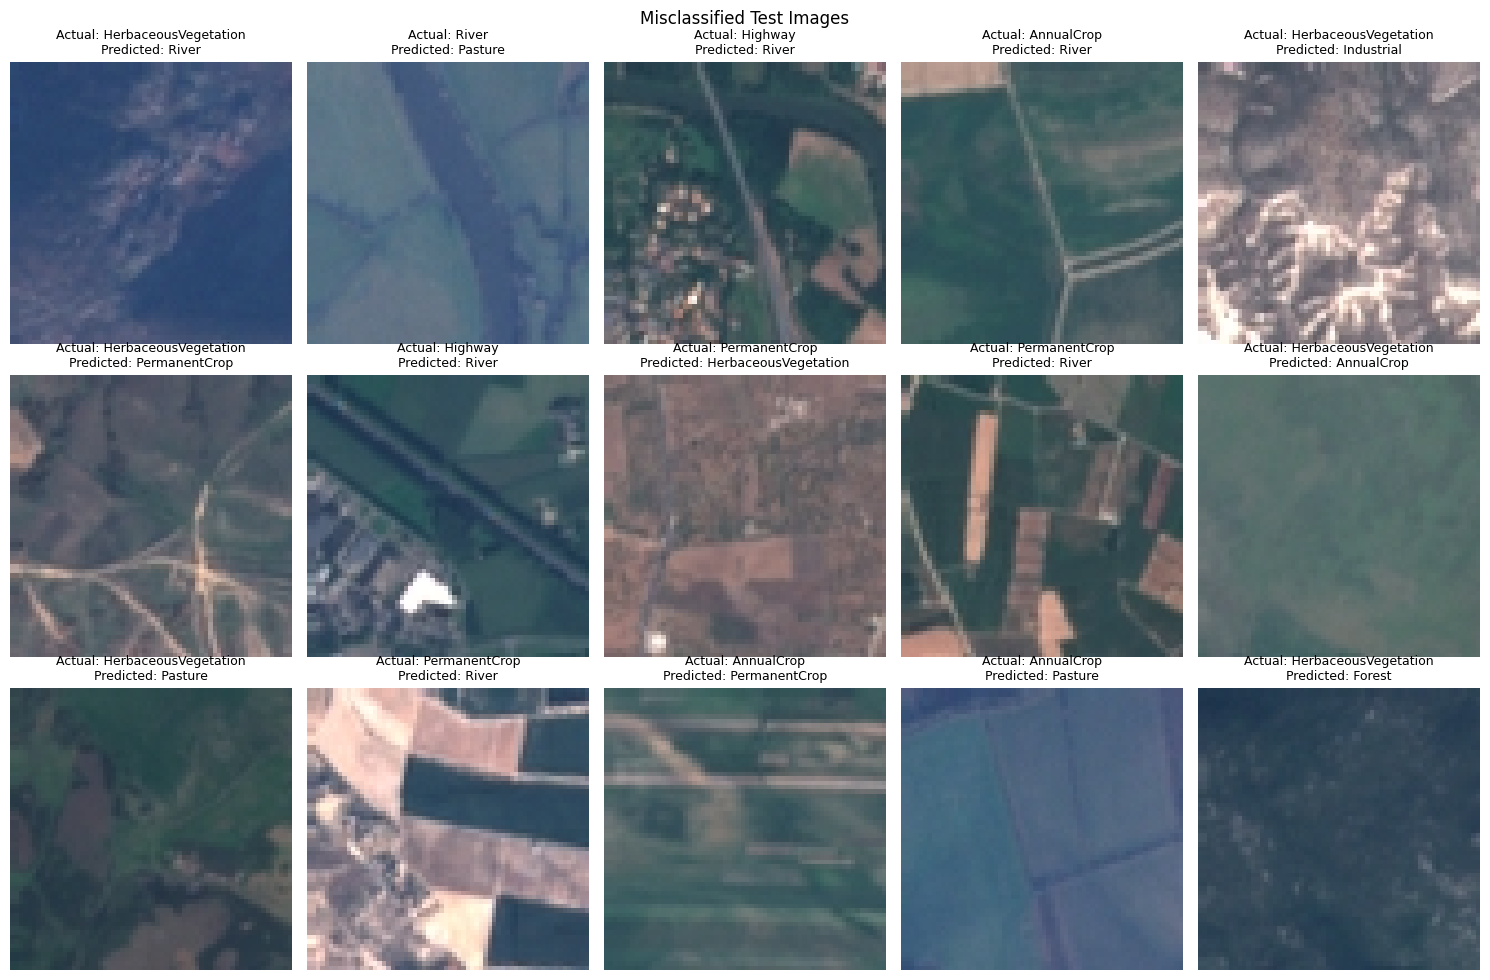


PROJECT COMPLETED
Model, classification report and confusion-pair results saved.


In [2]:

# ============================================================
# PS-26: EURO SAT RGB LAND USE CLASSIFICATION
# Train CNN, evaluate results, analyze confusion pairs
# ============================================================

import os
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models
from google.colab import files

# -------------------- CONFIGURATION --------------------

SEED = 42
BATCH_SIZE = 64
EPOCHS = 25
IMG_SIZE = (64, 64)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATASET_DIR = Path("/content/EuroSAT_RGB/EuroSAT_RGB")

class_names = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture", "PermanentCrop",
    "Residential", "River", "SeaLake"
]

# -------------------- 1. VERIFY DATASET --------------------

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_DIR}")

print("GPU:", tf.config.list_physical_devices("GPU"))

image_paths = []
labels = []

extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}

for label, class_name in enumerate(class_names):
    folder = DATASET_DIR / class_name

    if not folder.exists():
        raise FileNotFoundError(f"Missing class folder: {folder}")

    paths = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    ]

    print(f"{class_name}: {len(paths)} images")

    image_paths.extend([str(p) for p in paths])
    labels.extend([label] * len(paths))

image_paths = np.array(image_paths)
labels = np.array(labels, dtype=np.int32)

if len(labels) == 0:
    raise RuntimeError("No images found in the class folders.")

print("\nTotal images:", len(labels))
print("Number of classes:", len(np.unique(labels)))

# -------------------- 2. STRATIFIED SPLIT --------------------

all_idx = np.arange(len(labels))

train_idx, temp_idx = train_test_split(
    all_idx,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_idx]
)

print("\nTraining:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

# -------------------- 3. IMAGE LOADER --------------------

def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    # Decode standard JPEG/PNG images
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

def make_dataset(indices, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths[indices], labels[indices])
    )

    if training:
        ds = ds.shuffle(
            len(indices), seed=SEED, reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_idx, training=True)
val_ds = make_dataset(val_idx)
test_ds = make_dataset(test_idx)

# -------------------- 4. CLASS DISTRIBUTION AND CLASS-WISE SAMPLES --------------------

class_counts = pd.Series(labels).value_counts().reindex(range(len(class_names)), fill_value=0)
plt.figure(figsize=(12, 5))
plt.bar(class_names, class_counts.values)
plt.title("EuroSAT RGB: Images per Class")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Show one actual training image from every class (not merely 10 random images).
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for class_id, ax in enumerate(axes.flat):
    candidates = train_idx[labels[train_idx] == class_id]
    sample_idx = int(candidates[0])
    img, label = next(iter(make_dataset(np.array([sample_idx]))))
    ax.imshow(np.clip(img[0].numpy() / 255.0, 0, 1))
    ax.set_title(class_names[int(label[0])])
    ax.axis("off")
plt.suptitle("One Training Sample from Each EuroSAT Class")
plt.tight_layout()
plt.show()

# -------------------- 5. BUILD CNN --------------------

augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10)
], name="augmentation")

model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    layers.Rescaling(1.0 / 255),
    augmentation,

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# -------------------- 6. TRAIN --------------------

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_eurosat_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# -------------------- 7. TRAINING GRAPHS --------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# -------------------- 8. TEST EVALUATION --------------------

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("\n========== TEST RESULTS ==========")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

# -------------------- 9. PREDICTIONS --------------------

y_true = np.concatenate([
    y.numpy() for _, y in test_ds
])

probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probs, axis=1)

# -------------------- 10. CLASSIFICATION REPORT --------------------

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(10),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
print("\n========== CLASSIFICATION REPORT ==========")
print(report_df.round(4).to_string())

report_df.to_csv("/content/classification_report.csv")

# -------------------- 11. CONFUSION MATRIX --------------------

cm = confusion_matrix(y_true, y_pred, labels=np.arange(10))

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("EuroSAT RGB Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# -------------------- 12. CONFUSED CLASS PAIRS --------------------

pairs = []

for i in range(10):
    for j in range(i + 1, 10):
        a_to_b = int(cm[i, j])
        b_to_a = int(cm[j, i])

        pairs.append({
            "Class 1": class_names[i],
            "Class 2": class_names[j],
            "Class 1 -> Class 2": a_to_b,
            "Class 2 -> Class 1": b_to_a,
            "Total Confusions": a_to_b + b_to_a
        })

pairs_df = pd.DataFrame(pairs).sort_values(
    "Total Confusions", ascending=False
).reset_index(drop=True)

pairs_df.to_csv(
    "/content/most_confused_class_pairs.csv", index=False
)

print("\n========== TOP 10 CONFUSED CLASS PAIRS ==========")
print(pairs_df.head(10).to_string(index=False))

top = pairs_df.head(10).copy()
top["Pair"] = top["Class 1"] + " <-> " + top["Class 2"]

plt.figure(figsize=(12, 6))
sns.barplot(data=top, x="Total Confusions", y="Pair")
plt.title("Top 10 Most Confused Class Pairs")
plt.xlabel("Number of errors in both directions")
plt.tight_layout()
plt.show()

# -------------------- 13. DISPLAY WRONG PREDICTIONS --------------------

wrong_positions = np.where(y_true != y_pred)[0]

if len(wrong_positions):
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(
        wrong_positions,
        size=min(15, len(wrong_positions)),
        replace=False
    )

    # Reconstruct the exact test order for visualization
    test_paths = image_paths[test_idx]

    fig, axes = plt.subplots(3, 5, figsize=(15, 10))

    for ax in axes.flat:
        ax.axis("off")

    for ax, pos in zip(axes.flat, chosen):
        image = tf.io.decode_image(
            tf.io.read_file(test_paths[pos]),
            channels=3,
            expand_animations=False
        ).numpy()

        ax.imshow(image)
        ax.set_title(
            f"Actual: {class_names[y_true[pos]]}\n"
            f"Predicted: {class_names[y_pred[pos]]}",
            fontsize=9
        )

    plt.suptitle("Misclassified Test Images")
    plt.tight_layout()
    plt.show()

# -------------------- 14. SAVE AND DOWNLOAD RESULTS --------------------

model.save("/content/eurosat_land_cover_model.keras")

with zipfile.ZipFile(
    "/content/eurosat_project_results.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    for path in [
        "/content/eurosat_land_cover_model.keras",
        "/content/classification_report.csv",
        "/content/most_confused_class_pairs.csv"
    ]:
        z.write(path, arcname=os.path.basename(path))

print("\nPROJECT COMPLETED")
print("Model, classification report and confusion-pair results saved.")
# Download the ZIP manually from the Colab Files panel after execution, or run:
# from google.colab import files
# files.download("/content/eurosat_project_results.zip")


## Error analysis: representative misclassifications

The next cell displays one real test-set example for each of four frequent error types. Interpret the individual images carefully: the notes below are plausible explanations based on the class definitions and image scale, not proof of the model’s internal reasoning.

- **Herbaceous vegetation → Residential:** small patches can include both green cover and built-up edges, making mixed land cover difficult to label.
- **Herbaceous vegetation → Permanent crop:** both can appear green; regular planting patterns and field structure may be hard to resolve in a 64 × 64 RGB patch.
- **Highway → River:** both may form elongated linear structures, and nearby terrain, shadows, or patch boundaries can obscure the distinction.
- **Industrial → Residential:** both may contain roofs and dense built surfaces; industrial-scale layouts may not be fully visible in a small patch.

When you write the report, describe what is visibly present in each displayed example and avoid claiming these explanations are certain.


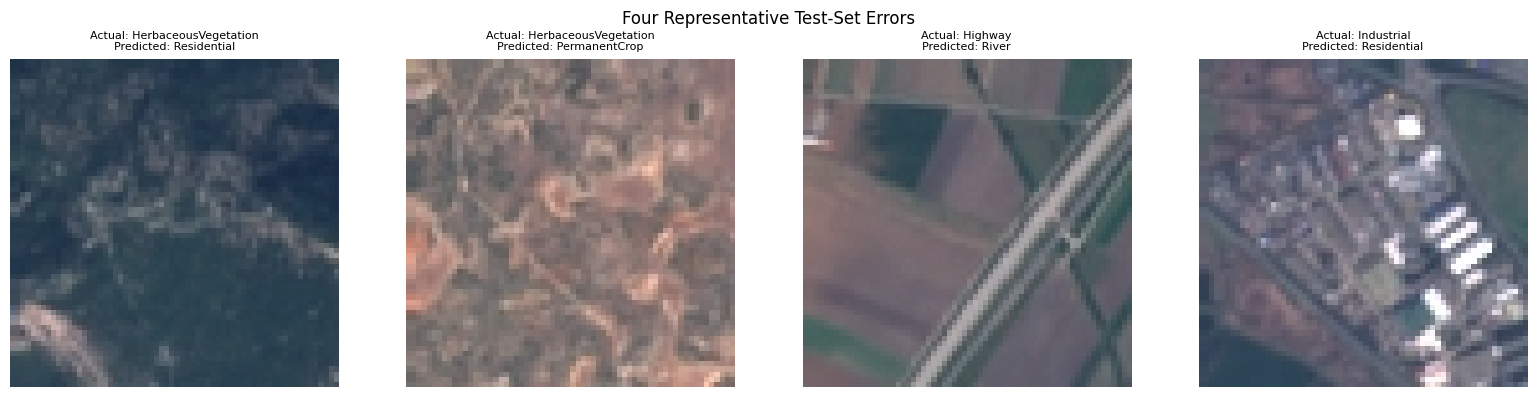

In [3]:
# Display one test-set example for each of four common error directions.
# The search is performed only in the held-out test predictions.
error_examples = [
    ("HerbaceousVegetation", "Residential"),
    ("HerbaceousVegetation", "PermanentCrop"),
    ("Highway", "River"),
    ("Industrial", "Residential"),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (actual_name, predicted_name) in zip(axes, error_examples):
    actual_id = class_names.index(actual_name)
    predicted_id = class_names.index(predicted_name)
    matches = np.where((y_true == actual_id) & (y_pred == predicted_id))[0]
    if len(matches) == 0:
        ax.text(0.5, 0.5, "No example found\nfor this direction", ha="center", va="center")
        ax.axis("off")
        continue
    pos = int(matches[0])
    test_paths = image_paths[test_idx]
    image = tf.io.decode_image(tf.io.read_file(test_paths[pos]), channels=3, expand_animations=False).numpy()
    ax.imshow(image)
    ax.set_title(f"Actual: {actual_name}\nPredicted: {predicted_name}", fontsize=8)
    ax.axis("off")
plt.suptitle("Four Representative Test-Set Errors")
plt.tight_layout()
plt.show()


## Dataset citation and AI-use declaration

**Dataset:** Helber, P. et al. (2019). *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*. IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing. Dataset record: https://zenodo.org/records/7711810

**AI assistance declaration (edit to match your actual use):** Generative AI was used to assist with code review, notebook organization, and drafting explanatory text. The student reviewed the notebook, executed the experiment, checked the outputs, and is responsible for the submitted work.

**Limitation:** this is a random stratified patch split. It does not establish performance on geographically separate regions or different acquisition conditions.
